# Assignment 3: Predictive Analytics

In [1]:
# importing data & dependencies
from pathlib import Path
import pandas as pd
import numpy as np
import sklearn as sk



# Define the paths relative to your notebook's directory
clinic_path = Path("data") / "clinic_appointments_O712.xlsx"
newapp_path = Path("data") / "new_appointments_O712.xlsx"

# Load both into separate DataFrames
df_clinic = pd.read_excel(clinic_path)
df_newapp = pd.read_excel(newapp_path)

In [2]:
#Highlevel scan of the data

# df_clinic.head(5)
# df_clinic.info()
# print(df_clinic.duplicated().sum())
# print(df_clinic.isna().sum()) #wait_time_min 1021
# df_clinic.describe()
df_clinic.sample(5)

,appointment_id,booking_date,appointment_date,appointment_hour,service,age,sex,distance_km,new_patient,prior_appointments,prior_no_shows,booking_channel,coverage,patient_fee_cad,sms_reminder,wait_time_min,status
607,A100507,2025-02-08,2025-02-10,8,Physiotherapy,95,F,3.4,0,10,3,Phone,Provincial plan,0,0,19.0,Attended
4950,A104485,2025-10-11,2025-10-31,15,Dermatology,48,M,9.7,1,0,0,Phone,Self-pay,85,1,14.0,Attended
5840,A104267,2025-12-24,2025-12-26,16,Family medicine,81,M,12.7,0,5,0,Phone,Provincial plan,0,1,24.0,Attended
380,A100847,2025-01-07,2025-01-27,16,Dermatology,81,F,8.8,0,5,3,Online portal,Self-pay,150,0,0.0,No-show
5480,A105197,2025-11-07,2025-12-02,15,Diagnostic imaging,35,F,12.1,0,9,2,Phone,Self-pay,120,1,14.0,Attended


## Part 1: Framing and fitting a classifier

#### A) *Based on the note, what exactly should your model predict?*
- The note is centred around predicting "No-shows", as the support staff are unable to fill the appointment slot given that there is no prior warning until the moment a no-show is realized.
- The target variable is transformed into a binary, with the other variables treated as the non-relevant values (O).
- Based on the data, we are trying to predict around 13.5% of the cases, which is about 1/7.5 cases.

#### B) *Which columns to exclude from the features*
- First, we must exclude the target column (no_show), along with anything that may lead to leakage: status and wait_time.
- We can also exclude appointment_id and the booking/appointment date, as the former is an arbitrary unique ID and the latter are raw dates with no predictive power unless transformed into a feature.

#### C) *Split the data into 70% training and 30% test -  Fit the workflow on the training set and show the confusion matrix on the test set using the default threshold*
- See cell 7
- We can see that the confusion matrix only raised the flag 34 times, of which only half were valid; as such, this model is not very precise.

#### D) *Compare the analysts accuracy with your model’s*
- The analyst’s model predicts that no appointment in the test set will be a no-show. It gets all 1,557 attended or cancelled appointments right and all 243 no-shows wrong, for an accuracy of 1,557 / 1,800 = 0.865.
- Whereas the logisitic model also scores  0.865. It correctly flags 17 no-shows, but it also wrongly flags 17 appointments that turned out fine. 
- With respect to accuracy, the models are on par; however, from the business's perspective, accuracy isn't useful, whereas as our model was able to flag 17/243 no-shows. 


In [3]:
# Code for A

# creating our target variable
df_clinic['no_show'] = (df_clinic['status'] == 'No-show').astype(int)

# Measuring repsective counts and average
print(df_clinic['no_show'].value_counts())
print(f"No-show share: {df_clinic['no_show'].mean():.2%}")

no_show
0    5191
1     809
Name: count, dtype: int64
No-show share: 13.48%


[[1540   17]
 [ 226   17]]


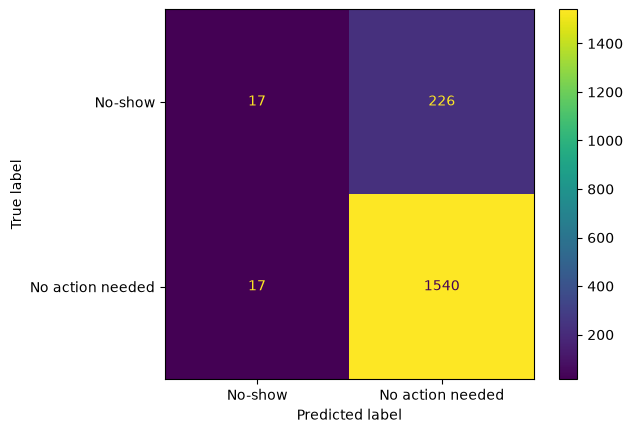

In [5]:
#Code for part C

# Importing dependencies

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# Define features (X) and target (y) from df_clinic
cols_to_drop = [
    'appointment_id',
    'booking_date',
    'appointment_date',
    'wait_time_min',
    'status',
    'no_show'
]

# Features and target
X = df_clinic.drop(columns=cols_to_drop)
y = df_clinic['no_show']

# 70/30 split, stratified so both sets keep the same no-show share
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# Split columns by type
cat_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()

# Preprocessing: scale numeric, one-hot encode categorical
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# Workflow = preprocessing + classifier
logit_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

logit_pipe.fit(X_train, y_train)

# Confusion matrix on the test set at the default 0.5 threshold
y_pred = logit_pipe.predict(X_test)

print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[1, 0],
    display_labels=['No-show', 'No action needed']
)


## Part 2:  Matching the measure to the decision

#### A) *Reminder Calls*

- The appropriate measure here would be **recall**, which is the share of patients who didn’t show up that the list flags. The business stated a preference for catching no-shows (true positives) over missing a no-show, a false negative.
- At the current default threshold (0.5), we see a recall of 7% (17/243).
- The revised threshold that raises recall to her desired 3/4 catch rate is **between 0.11 and 0.12** At a threshold of 0.11, we see recall increase to 0.77 (187 / 243). We see false negatives decrease to 56, true positives increase to 187, and false positives increase to 615. 
- In practice, the office spends more time calling patients who would have shown up anyway, to the benefit of catching an additional 170 patients who would have no-showed.

#### B) *Double-booking*
- The appropriate measure here would be **precision**, which is a measure of the accurate of postive predictions (correctly flagged no shows). In this scenario, the manager wants to ensure that the at least 50% of the flagged cases do not show up.
- Raising the threshold to **0.56** increases precision to 63.0% (17/27). The list shrinks from 34 to 27 appointments, and all 7 that drop off were false positives, so the clinic keeps every no-show it was catching while avoiding 7 double-bookings where a patient would have waited an hour.
- In practice, the clinic gives up coverage. The list catches only 17 of the 243 no-shows (recall of 7.0%), so double-booking can fill at most 17 empty slots, and the other 226 stay empty. 


#### c) *Choosing a vendor*

- The appropriate measure here would be **F1**, which combines precision and recall into a single score. Because the clinic hasn't decided between reminder calls and double-booking, both mistakes matter.
- At the current default threshold (0.5), we see an F1 of 0.123 (2×17 / (2×17 + 17 + 226) = 34/277). 
- Lowering the threshold to **0.15** raises F1 to its highest value of 0.391 (2×159 / (2×159 + 411 + 84) = 318/813). The difference in F1 is marginal, ranging from 0.14 to 0.26; once the manager decides how to use the model, she can move within this range toward recall or precision with little loss in F1.
- In practice, the clinic gives up the strengths of the more specialized thresholds. At 0.15, the list grows from 34 to 570 appointments (31.7% of 1,800) and catches 159 no-shows instead of 17, but precision falls from 50.0% to 27.9% (159/570). As such, this threshold is a compromise that meets neither earlier requirement but enables her to weigh the trade-offs.

In [ ]:
#Code for Part 2, various thresholds tested in a trial-and-error fashion to determine the appropriate score for parts a:c.

from sklearn.metrics import recall_score, precision_score, f1_score

probs = logit_pipe.predict_proba(X_test)[:, 1]

# Part A) At a threshold of 0.11, recall returns a value of 0.77; at a threshold of 12, it returns a recall value of 0.733.
# Part B) At a threshold of 0.57, precision returns a value of 0.630.
# Part C) At a threshold of 0.15 F1 returns a value of 0.391, at a threshold of 0.26, F1 is a value of 0.386 - very little change takes place between this range.

threshold = 0.26

y_pred_t = (probs >= threshold).astype(int)
print(f"Threshold: {threshold}")
print(f"Recall:    {recall_score(y_test, y_pred_t):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_t, zero_division=0):.3f}")
print(f"F1:        {f1_score(y_test, y_pred_t):.3f}")
print(f"Flagged:   {y_pred_t.sum()}")
print(confusion_matrix(y_test, y_pred_t, labels=[1, 0]))

Threshold: 0.26
Recall:    0.366
Precision: 0.408
F1:        0.386
Flagged:   218
[[  89  154]
 [ 129 1428]]
